In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

project = Path.cwd().parent

df = pd.read_csv(
    project / "Data-raw" / "Telco-Customer-Churn-Cleaned.csv"
)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


PaymentMethod Analysis

In [2]:
print(df["PaymentMethod"].value_counts())

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64


Calculate churn rate

In [3]:
payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

display(payment_churn.round(2))

PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64

Visualize churn by payment method

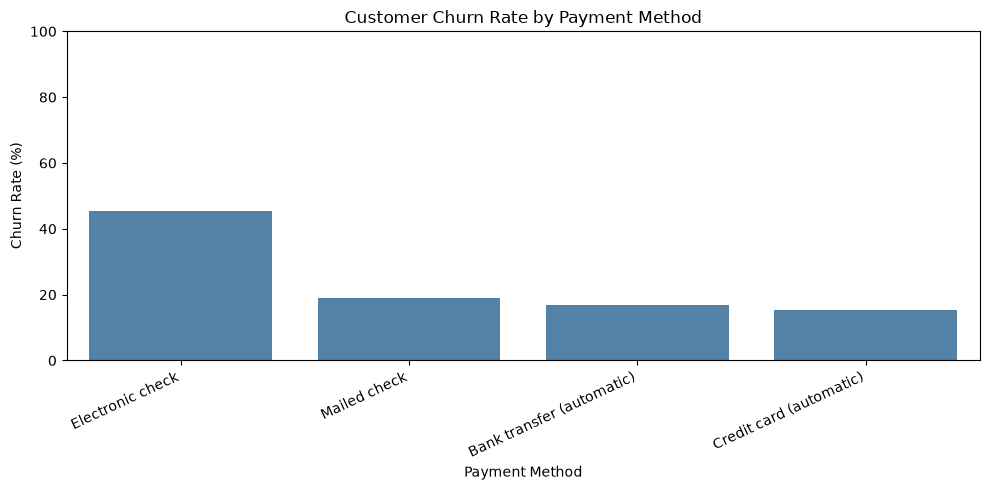

In [4]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=payment_churn.index,
    y=payment_churn.values,
    color="steelblue"
)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

PaperlessBilling Analysis

In [5]:
paperless_churn = (
    df.groupby("PaperlessBilling")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

display(paperless_churn.round(2))

PaperlessBilling
No     16.33
Yes    33.57
Name: Churn, dtype: float64

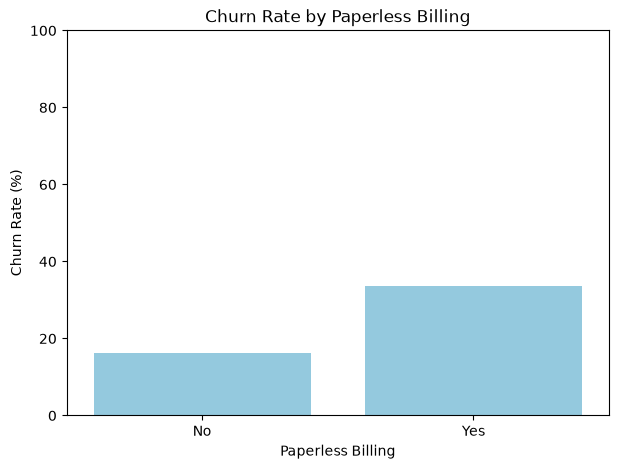

In [6]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=paperless_churn.index,
    y=paperless_churn.values,
    color="skyblue"
)

plt.title("Churn Rate by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

plt.show()

Gender Analysis

In [7]:
gender_churn = (
    df.groupby("gender")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

display(gender_churn.round(2))

gender
Female    26.92
Male      26.16
Name: Churn, dtype: float64

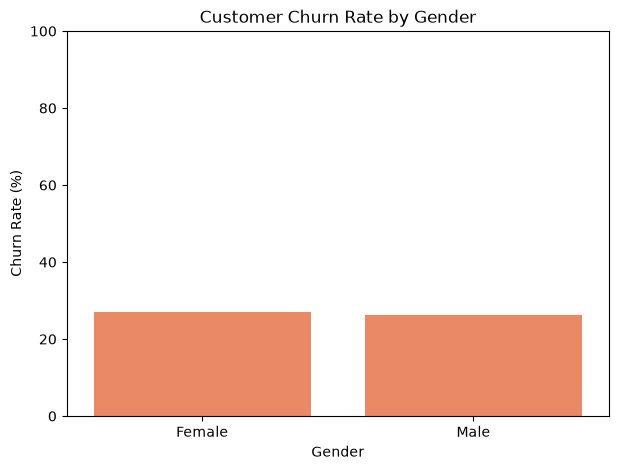

In [8]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=gender_churn.index,
    y=gender_churn.values,
    color="coral"
)

plt.title("Customer Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

plt.show()

SeniorCitizen Analysis

In [9]:
senior_churn = (
    df.groupby("SeniorCitizen")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

display(senior_churn.round(2))

SeniorCitizen
0    23.61
1    41.68
Name: Churn, dtype: float64

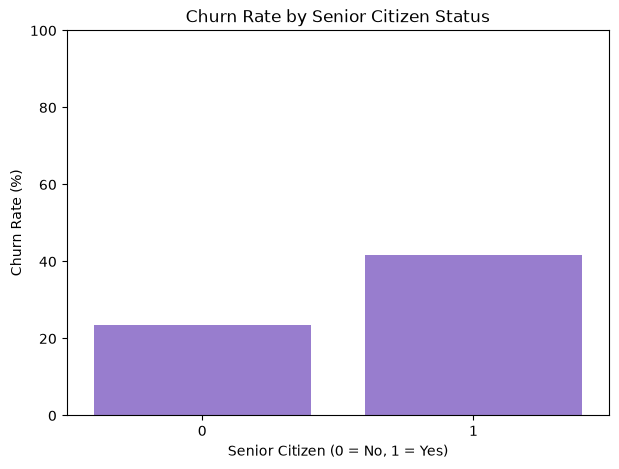

In [10]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=senior_churn.index,
    y=senior_churn.values,
    color="mediumpurple"
)

plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

plt.show()

Partner and Dependents Analysis

In [11]:
partner_churn = (
    df.groupby("Partner")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

display(partner_churn.round(2))

Partner
No     32.96
Yes    19.66
Name: Churn, dtype: float64

Dependents churn rate

In [12]:
dependents_churn = (
    df.groupby("Dependents")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

display(dependents_churn.round(2))

Dependents
No     31.28
Yes    15.45
Name: Churn, dtype: float64

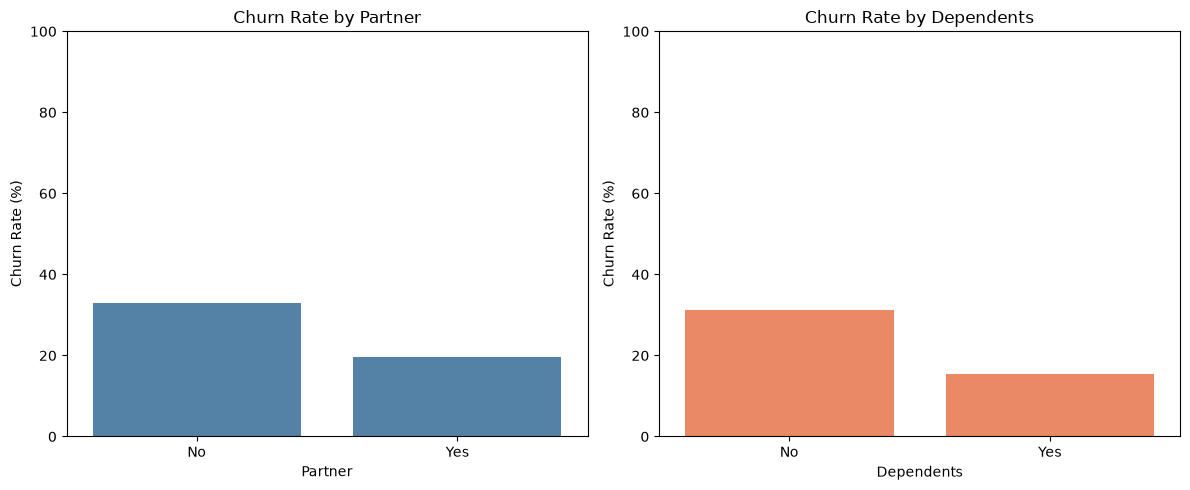

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    x=partner_churn.index,
    y=partner_churn.values,
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Churn Rate by Partner")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].set_ylim(0, 100)

sns.barplot(
    x=dependents_churn.index,
    y=dependents_churn.values,
    ax=axes[1],
    color="coral"
)

axes[1].set_title("Churn Rate by Dependents")
axes[1].set_ylabel("Churn Rate (%)")
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

Create all six graphs together

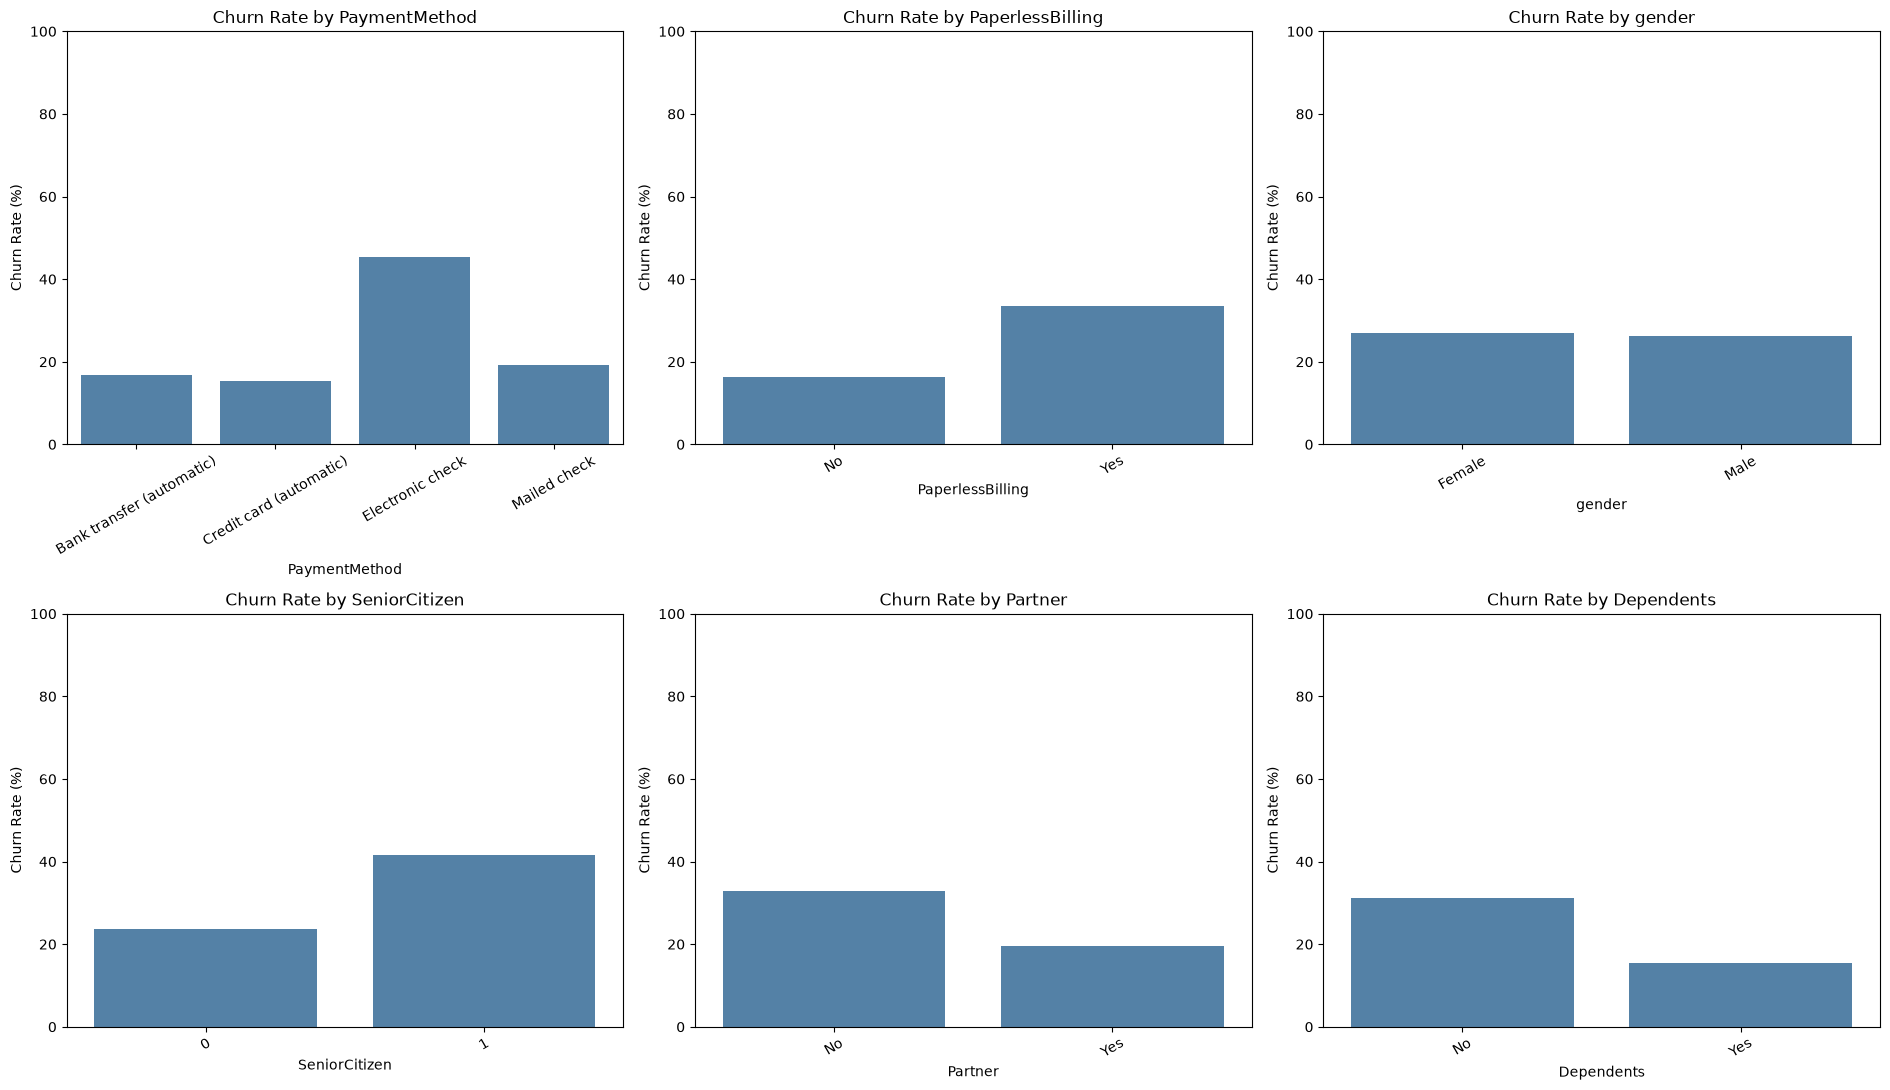

In [14]:
features = [
    "PaymentMethod",
    "PaperlessBilling",
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

fig, axes = plt.subplots(2, 3, figsize=(19, 11))

for ax, feature in zip(axes.flatten(), features):

    churn_rate = (
        df.groupby(feature)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
    )

    sns.barplot(
        x=churn_rate.index.astype(str),
        y=churn_rate.values,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(f"Churn Rate by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Churn Rate (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

Generate Business Summary Table

In [15]:
summary_list = []

for feature in features:

    summary = (
        df.groupby(feature)["Churn"]
        .agg(
            Customers="count",
            Churned=lambda x: (x == "Yes").sum()
        )
        .reset_index()
    )

    summary["ChurnRate"] = (
        summary["Churned"] /
        summary["Customers"] * 100
    )

    summary["Feature"] = feature

    summary = summary.rename(
        columns={feature: "Category"}
    )

    summary["Category"] = summary["Category"].astype(str)

    summary_list.append(
        summary[
            [
                "Feature",
                "Category",
                "Customers",
                "Churned",
                "ChurnRate"
            ]
        ]
    )

demographics_summary = pd.concat(
    summary_list,
    ignore_index=True
)

display(demographics_summary.round(2))

,Feature,Category,Customers,Churned,ChurnRate
0,PaymentMethod,Bank transfer (automatic),1544,258,16.71
1,PaymentMethod,Credit card (automatic),1522,232,15.24
2,PaymentMethod,Electronic check,2365,1071,45.29
3,PaymentMethod,Mailed check,1612,308,19.11
4,PaperlessBilling,No,2872,469,16.33
5,PaperlessBilling,Yes,4171,1400,33.57
6,gender,Female,3488,939,26.92
7,gender,Male,3555,930,26.16
8,SeniorCitizen,0,5901,1393,23.61
9,SeniorCitizen,1,1142,476,41.68


Save your CSV report

In [16]:
from pathlib import Path

project = Path.cwd().parent

report_folder = project / "Report"

report_folder.mkdir(
    parents=True,
    exist_ok=True
)

report_file = (
    report_folder /
    "payment_demographics_churn_summary.csv"
)

demographics_summary.to_csv(
    report_file,
    index=False
)

print("Report saved successfully!")
print("File exists:", report_file.exists())
print("Location:", report_file.resolve())

Report saved successfully!
File exists: True
Location: C:\Users\yashr\OneDrive\Documents\AI CUSTOMER PREDICTION CHURN\Report\payment_demographics_churn_summary.csv


Verify the saved CSV

In [17]:
saved_report = pd.read_csv(report_file)

display(saved_report.head())

print("Saved report shape:", saved_report.shape)

,Feature,Category,Customers,Churned,ChurnRate
0,PaymentMethod,Bank transfer (automatic),1544,258,16.709845
1,PaymentMethod,Credit card (automatic),1522,232,15.243101
2,PaymentMethod,Electronic check,2365,1071,45.285412
3,PaymentMethod,Mailed check,1612,308,19.106700
4,PaperlessBilling,No,2872,469,16.330084


Saved report shape: (14, 5)
